# FDA Week 04 Assignment v2
## 거래량 기반 기술적 분석, 통합 투자전략과 위험관리

학생은 KOSPI200 PIT 데이터셋에서 **한 종목을 자유롭게 선택**합니다.

단, Lab 예제인 삼성전자(`005930`)는 제외합니다.


## 공통 규칙

- 거래정지일은 indicator/execution clock에서 제외
- adjusted OHLCV 사용
- burn-in 120 거래일
- next-trading-day open execution
- COMP / COMP_RM 공통 명세 준수
- 마지막 2년 OOS
- baseline과 OOS 모두 동일 규칙


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from FDA_week04_reference_v21 import (
    prepare_single_stock,
    build_indicators,
    correlation_inputs,
    public_indicator_sanity,
)

DATA_FILE = Path("FDA_kospi200_daily.parquet")
df_all = pd.read_parquet(DATA_FILE)

df_all["Date"] = pd.to_datetime(df_all["Date"])
df_all["Symbol"] = (
    df_all["Symbol"]
    .astype("string")
    .str.zfill(6)
)

# TODO: 삼성전자(005930)를 제외하고 종목 선택
SYMBOL = "000660"


## Task 1. 종목 선택과 데이터 검증

다음을 출력하고 선택 이유를 설명하십시오.

- Symbol
- Name
- 분석기간
- raw rows
- trading-day rows
- 거래정지/non-trading rows


In [2]:
# TODO
# 전처리 전(raw)과 거래일만 남긴(trading) 두 버전을 만든다.
raw = prepare_single_stock(df_all, SYMBOL, trading_only=False)
trd = prepare_single_stock(df_all, SYMBOL, trading_only=True)
non = raw.loc[~raw["TradingDay"]]   # 거래정지 / non-trading rows

print("Symbol            :", SYMBOL)
print("Name              :", raw["Name"].iloc[-1])
print("분석기간 (raw)     :", raw["Date"].min().date(), "~", raw["Date"].max().date())
print("분석기간 (trading) :", trd["Date"].min().date(), "~", trd["Date"].max().date())
print("raw rows          :", len(raw))
print("trading-day rows  :", len(trd))
print("non-trading rows  :", len(non), f"({len(non)/len(raw):.2%})")

# 거래정지 구간 확인
print(non[["Date", "Open", "Close", "AdjustedClose", "Volume"]])


Symbol            : 000660
Name              : SK하이닉스
분석기간 (raw)     : 2001-01-02 ~ 2025-12-30
분석기간 (trading) : 2001-01-02 ~ 2025-12-30
raw rows          : 6168
trading-day rows  : 6156
non-trading rows  : 12 (0.19%)
          Date   Open  Close  AdjustedClose  Volume
549 2003-03-27  135.0  135.0         2650.0     0.0
550 2003-03-28  135.0  135.0         2650.0     0.0
551 2003-03-31  135.0  135.0         2650.0     0.0
552 2003-04-01  135.0  135.0         2650.0     0.0
553 2003-04-02  135.0  135.0         2650.0     0.0
554 2003-04-03  135.0  135.0         2650.0     0.0
555 2003-04-04  135.0  135.0         2650.0     0.0
556 2003-04-07  135.0  135.0         2650.0     0.0
557 2003-04-08  135.0  135.0         2650.0     0.0
558 2003-04-09  135.0  135.0         2650.0     0.0
559 2003-04-10  135.0  135.0         2650.0     0.0
560 2003-04-11  135.0  135.0         2650.0     0.0


### 종목선택 이유
SK하이닉스는 KOSPI200 대표 대형주입니다. 2001년부터 2025년까지 약 25년, 6,000여 거래일의 데이터가 있어 burn-in 120일을 빼고도 IS/OOS 분할에 충분합니다. 거래량이 풍부해 거래량 기반 지표(VolumeRatio, OBV, MFI)가 안정적으로 계산됩니다. 또 2003년에 12거래일의 거래정지 구간이 있어, 과제의 핵심 주제인 "거래정지일을 indicator/execution clock에서 제외"하는 처리가 실제로 필요한 종목입니다. 삼성전자와 같은 반도체 업종이지만 변동성이 더 커서 COMP와 COMP_RM의 위험관리 효과를 비교하기에 적합합니다.

## Task 2. adjusted OHLCV와 거래량 지표

- VolumeRatio20
- TradingValueRatio20
- OBV
- MFI14

기업행동과 거래정지가 지표 계산에 왜 중요한지 설명하십시오.


In [3]:
# 거래일만 남기고 지표를 계산한다. (build_indicators는 거래정지일이 섞여 있으면 에러를 낸다)
trd = prepare_single_stock(df_all, SYMBOL, trading_only=True)
ind = build_indicators(trd)

vol_cols = ["Date", "AdjustedClose", "AdjVolume",
            "VolumeRatio20", "TradingValueRatio20", "OBV", "MFI14"]

print("[마지막 10행]")
print(ind[vol_cols].tail(10).to_string(index=False))

print("\n[요약 통계]")
print(ind[["VolumeRatio20", "TradingValueRatio20", "OBV", "MFI14"]].describe().T)

print("\n[결측치 수]")
print(ind[["VolumeRatio20", "TradingValueRatio20", "OBV", "MFI14"]].isna().sum())

print("\n[sanity check]")
print(public_indicator_sanity(ind))

[마지막 10행]
      Date  AdjustedClose  AdjVolume  VolumeRatio20  TradingValueRatio20          OBV     MFI14
2025-12-16       530000.0  3287998.0       0.876809             0.864381 2.244243e+09 42.350371
2025-12-17       551000.0  2692626.0       0.736071             0.727607 2.246935e+09 40.977028
2025-12-18       552000.0  2959059.0       0.828277             0.844715 2.249894e+09 47.944957
2025-12-19       547000.0  3440005.0       1.008146             1.030781 2.246454e+09 55.939842
2025-12-22       580000.0  2878464.0       0.889465             0.930974 2.249333e+09 56.272869
2025-12-23       584000.0  2011188.0       0.638290             0.677958 2.251344e+09 62.152392
2025-12-24       588000.0  2160697.0       0.719617             0.760798 2.253505e+09 68.644526
2025-12-26       599000.0  4243548.0       1.399570             1.495208 2.257748e+09 71.867341
2025-12-29       640000.0  4176151.0       1.344181             1.500330 2.261924e+09 72.133752
2025-12-30       651000.0  409

### 기업행동과 거래정지가 지표계산에 왜 중요한지
거래량 지표는 모두 오늘의 가격·거래량을 과거 며칠과 비교해 계산하므로, 비교하는 날들이 같은 단위이고 실제로 거래된 날이어야 합니다.

기업행동(액면분할, 감자 등)은 회사 가치와 무관하게 주식 수를 바꿔, 기업행동 전후의 가격과 거래량을 서로 다른 단위로 만듭니다. 이대로 비교하면 VolumeRatio20에는 가짜 급증·급감이, OBV와 MFI14에는 가짜 급등락에 따른 잘못된 방향이 생깁니다. 그래서 가격에는 수정계수를 곱하고 거래량은 수정계수로 나눠 단위를 맞춥니다. 000660은 2003-03-26 원래 종가 135원, 수정종가 2,650원(수정계수 약 19.6)이며, 수정 후 거래량(약 1,293만 주)이 재개일(약 1,217만 주)과 같은 규모로 이어집니다.

거래정지일은 거래가 없었던 날이라, 비교 대상에 들어가면 지표가 왜곡됩니다. 거래량 0인 날이 20일 평균을 낮춰 재개 후 VolumeRatio20이 부풀려지고, MFI14는 유효한 날이 줄어 극단값이 나오기 쉽습니다. 또 그날은 체결도 할 수 없습니다. 그래서 000660의 2003-03-27 ~ 2003-04-11, 12일을 지표와 체결의 날짜 계산에서 모두 제외했습니다.

## Task 3. Indicator redundancy

SMA gap, MACD histogram, RSI, Volume Ratio, MFI, ATR% 상관행렬을 계산하고 중복성을 해석하십시오.


관측치 수: 6036 (burn-in 120일 제외)

            SMA gap  MACD hist  RSI14  VolRatio20  MFI14   ATR%
SMA gap       1.000     -0.108  0.509      -0.068  0.202 -0.396
MACD hist    -0.108      1.000  0.364       0.015  0.366 -0.056
RSI14         0.509      0.364  1.000       0.023  0.766 -0.321
VolRatio20   -0.068      0.015  0.023       1.000  0.008  0.069
MFI14         0.202      0.366  0.766       0.008  1.000 -0.125
ATR%         -0.396     -0.056 -0.321       0.069 -0.125  1.000

[|상관| 큰 쌍]
         A          B   corr
     RSI14      MFI14  0.766
   SMA gap      RSI14  0.509
   SMA gap       ATR% -0.396
 MACD hist      MFI14  0.366
 MACD hist      RSI14  0.364
     RSI14       ATR% -0.321
   SMA gap      MFI14  0.202
     MFI14       ATR% -0.125
   SMA gap  MACD hist -0.108
VolRatio20       ATR%  0.069
   SMA gap VolRatio20 -0.068
 MACD hist       ATR% -0.056
     RSI14 VolRatio20  0.023
 MACD hist VolRatio20  0.015
VolRatio20      MFI14  0.008


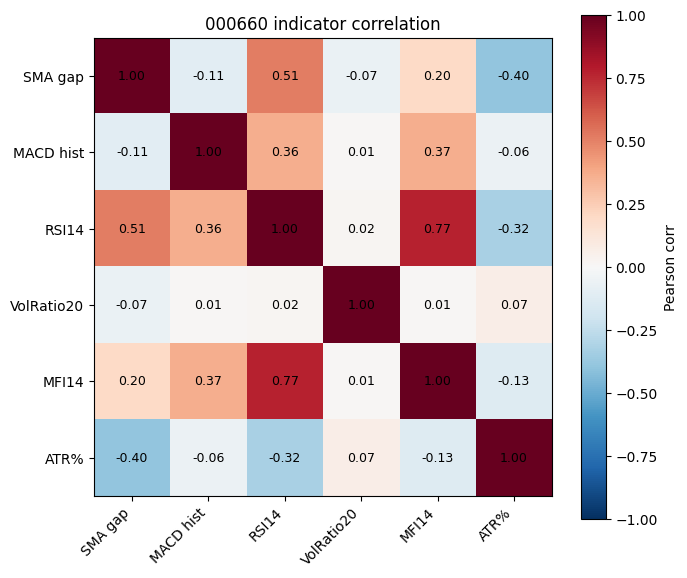

In [4]:
BURN_IN = 120
corr_df = correlation_inputs(ind.iloc[BURN_IN:]).dropna()

# 표기용 이름으로 변경
corr_df = corr_df.rename(columns={
    "SMA_Gap": "SMA gap", "MACD_Hist": "MACD hist", "RSI14": "RSI14",
    "VolumeRatio20": "VolRatio20", "MFI14": "MFI14", "ATR_Pct": "ATR%",
})

corr = corr_df.corr()   # Pearson
print(f"관측치 수: {len(corr_df)} (burn-in {BURN_IN}일 제외)\n")
print(corr.round(3))

# 상관 절댓값이 큰 쌍 순위
pairs = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
        .stack()
        .dropna()
        .rename("corr")
        .reset_index()
        .rename(columns={"level_0": "A", "level_1": "B"})
)
pairs["abs"] = pairs["corr"].abs()
print("\n[|상관| 큰 쌍]")
print(pairs.sort_values("abs", ascending=False).drop(columns="abs").round(3).to_string(index=False))

# 히트맵
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Pearson corr")
ax.set_title(f"{SYMBOL} indicator correlation")
plt.tight_layout()
plt.show()

### 지표 중복성 해석

- **중복이 뚜렷한 쌍은 RSI14와 MFI14(0.77)입니다.** 둘은 구조가 같고, MFI는 거래량이 가중된 RSI입니다. 두 지표를 모두 점수에 넣으면 사실상 같은 정보를 두 번 세는 셈입니다.
- **SMA gap과 RSI14는 중간 수준(0.51)입니다.** 둘 다 가격 추세를 반영하기 때문입니다.
- **VolRatio20은 다른 모든 지표와 거의 무상관입니다(절댓값 0.07 이하).** 가격 지표에는 없는 독립적인 정보를 준다는 뜻입니다.
- **ATR%는 SMA gap(-0.40), RSI(-0.32)와 음의 상관입니다.** 이 종목에서는 추세가 강하고 RSI가 높은 구간에서 변동성이 낮은 경향이 있었다는 뜻입니다. 인과를 말하는 것은 아닙니다.
- 이 상관은 25년 전체 기간 평균입니다. 시기에 따라 달라질 수 있고, 지표들이 시계열이라 자기상관이 커서 상관계수의 정밀도를 과신하면 안 됩니다. 

## Task 4. COMP state machine

학생이 직접 구현합니다.

- entry: Score>=2 AND RSI<70
- exit: Score<2
- next-trading-day AdjOpen execution
- transaction cost


In [5]:
BURN_IN = 120
ROUND_TRIP_COST = 0.0025   # 왕복 비용 c (편도 = c/2)


def run_comp(df, round_trip_cost=ROUND_TRIP_COST, burn_in=BURN_IN):
    """COMP 상태기계 (long-only, 비중 0 또는 1).

    - t일 종가 후 신호 판단 -> t+1일 AdjOpen에서 체결
    - FLAT : EntryCondition_COMP == 1  -> 다음 거래일 시가 진입
    - LONG : ExitCondition (Score < 2) -> 다음 거래일 시가 청산
    - 편도 비용 = round_trip_cost / 2 (체결이 일어난 날 수익률에서 차감)
    - 거래정지일은 이미 제외된 거래일 시계(df)에서만 동작
    """
    d = df.reset_index(drop=True)
    n = len(d)
    entry_sig = d["EntryCondition_COMP"].to_numpy(dtype=int)
    exit_sig = d["ExitCondition"].to_numpy(dtype=int)

    state_close = np.zeros(n, dtype=int)   # 종가 후 상태 (1=LONG, 0=FLAT)
    entry_exec = np.zeros(n, dtype=int)    # 해당일 시가에 진입 체결
    exit_exec = np.zeros(n, dtype=int)     # 해당일 시가에 청산 체결

    pending = 0   # 어제 종가 후 정해진 주문: +1 진입, -1 청산, 0 없음
    state = 0
    for t in range(n):
        # 1) 시가 체결 (전일 종가 후 신호)
        if pending == 1 and state == 0:
            state = 1
            entry_exec[t] = 1
        elif pending == -1 and state == 1:
            state = 0
            exit_exec[t] = 1
        pending = 0

        # 2) 종가 후 신호 판단 (burn-in 이후 평가 구간의 첫날 시가부터 체결 가능)
        if t >= burn_in - 1:
            if state == 0 and entry_sig[t] == 1:
                pending = 1
            elif state == 1 and exit_sig[t] == 1:
                pending = -1
        state_close[t] = state

    w_close = pd.Series(state_close, index=d.index, dtype=float)
    w_prev = w_close.shift(1).fillna(0.0)

    op = d["AdjOpen"].astype(float)
    cl = d["AdjustedClose"].astype(float)
    cl_prev = cl.shift(1)

    overnight = op / cl_prev - 1.0     # 전일 종가 -> 오늘 시가
    intraday = cl / op - 1.0           # 오늘 시가 -> 오늘 종가
    trade_cost = (round_trip_cost / 2.0) * (w_close - w_prev).abs()

    # 수익률은 곱(복리)으로 결합: (전일종가->시가) x (시가->종가)
    gross = (1.0 + w_prev * overnight.fillna(0.0)) * (1.0 + w_close * intraday) - 1.0
    out = d[["Date", "AdjOpen", "AdjustedClose", "Score", "RSI14"]].copy()
    out["EntryExec"] = entry_exec
    out["ExitExec"] = exit_exec
    out["WeightClose"] = w_close
    out["GrossReturn"] = gross
    out["StrategyReturn"] = (1.0 + gross) * (1.0 - trade_cost) - 1.0
    out.loc[: burn_in - 1, ["GrossReturn", "StrategyReturn"]] = 0.0   # burn-in은 평가 제외
    return out


comp = run_comp(ind, ROUND_TRIP_COST)
ev = comp.iloc[BURN_IN:]

n_trades = int(ev["EntryExec"].sum())
print("burn-in 제외 평가 구간:", ev["Date"].iloc[0].date(), "~", ev["Date"].iloc[-1].date())
print("n_trades (entry 체결 수):", n_trades)
print("exit 체결 수            :", int(ev["ExitExec"].sum()))
print("exposure (보유일 비율)   :", round(float(ev["WeightClose"].mean()), 4))
print("invested days           :", int(ev["WeightClose"].sum()))
print("누적수익률 (net)         :", round(float((1 + ev["StrategyReturn"]).prod() - 1), 4))
print("누적수익률 (gross)       :", round(float((1 + ev["GrossReturn"]).prod() - 1), 4))

# 체결 내역 확인 (신호일 다음 거래일 시가로 체결되는지)
fills = comp.loc[(comp["EntryExec"] == 1) | (comp["ExitExec"] == 1),
                 ["Date", "AdjOpen", "EntryExec", "ExitExec"]].copy()
fills["Type"] = np.where(fills["EntryExec"] == 1, "ENTRY", "EXIT")
print("\n[첫 10개 체결]")
print(fills[["Date", "Type", "AdjOpen"]].head(10).to_string(index=False))

# ---- 검증 ----
# (1) 룩어헤드 점검: 체결일의 "전날" 신호가 실제로 1이었는지
prev_entry = ind["EntryCondition_COMP"].shift(1)
prev_exit = ind["ExitCondition"].shift(1)
print("\n[검증]")
print("진입 체결일 전일 신호 불일치 수:", int((prev_entry[comp["EntryExec"] == 1] != 1).sum()))
print("청산 체결일 전일 신호 불일치 수:", int((prev_exit[comp["ExitExec"] == 1] != 1).sum()))

# (2) 거래별로 직접 복리 계산한 값 == 일별 수익률 복리 값인지
half = ROUND_TRIP_COST / 2
tr = comp.reset_index(drop=True)
eq, entry_px = 1.0, None
for i in tr.index[(tr["EntryExec"] == 1) | (tr["ExitExec"] == 1)]:
    if tr.loc[i, "EntryExec"] == 1:
        entry_px = tr.loc[i, "AdjOpen"]
    else:
        eq *= tr.loc[i, "AdjOpen"] * (1 - half) / entry_px * (1 - half)
        entry_px = None
if entry_px is not None:   # 마지막까지 보유 중이면 마지막 종가로 평가 (청산 비용 없음)
    eq *= tr["AdjustedClose"].iloc[-1] / entry_px * (1 - half)
daily = (1 + tr["StrategyReturn"]).prod()
print("거래별 복리:", round(eq, 6), "/ 일별 복리:", round(daily, 6),
      "/ 상대오차:", f"{abs(eq / daily - 1):.2e}")
print("마지막 날 보유 여부(WeightClose):", int(comp['WeightClose'].iloc[-1]))

burn-in 제외 평가 구간: 2001-06-28 ~ 2025-12-30
n_trades (entry 체결 수): 363
exit 체결 수            : 362
exposure (보유일 비율)   : 0.2984
invested days           : 1801
누적수익률 (net)         : 0.0828
누적수익률 (gross)       : 1.6815

[첫 10개 체결]
      Date  Type      AdjOpen
2001-08-07 ENTRY 33370.445104
2001-08-08  EXIT 33370.526316
2001-08-24 ENTRY 26107.211155
2001-08-28  EXIT 20512.538813
2001-09-14 ENTRY 23162.391960
2001-09-19  EXIT 18942.592593
2001-09-20 ENTRY 18942.167568
2001-09-21  EXIT 17273.967213
2001-10-08 ENTRY 21985.185185
2001-10-10  EXIT 21200.347826

[검증]
진입 체결일 전일 신호 불일치 수: 0
청산 체결일 전일 신호 불일치 수: 0
거래별 복리: 1.082826 / 일별 복리: 1.082826 / 상대오차: 8.88e-16
마지막 날 보유 여부(WeightClose): 1


## Task 5. COMP_RM

COMP에 다음을 추가합니다.

- HighVol gate
- ATR stop
- same-day stop
- gap stop
- signal reset


In [6]:
ATR_STOP_MULT = 2.0   # ATR stop 배수: StopPrice = EntryPrice - k * ATR(신호일)
                      # 과제 문서에 배수가 명시되어 있지 않다. toy 는 k=1.25~3.0 에서 모두 PASS(1.0, 3.25 는 FAIL)이므로
                      # toy 로는 k 가 확정되지 않는다. 이 범위 안에서 2.0 을 택했다. toy 에는 gap stop 사례가 없어 gap 로직은 toy 로 검증되지 않았다.


def run_state_machine_rm(o, h, l, c, entry_sig, score_lt2, atr_sig,
                         round_trip_cost=ROUND_TRIP_COST, atr_mult=ATR_STOP_MULT,
                         burn_in=0):
    """COMP_RM 상태기계 (long-only, 비중 0 또는 1).

    COMP 규칙 + 아래 위험관리 규칙
      - HighVol gate : entry_sig 에 이미 반영된 진입 조건 (HighVol==0)
      - ATR stop     : 진입가 - atr_mult * ATR(신호일) 고정 손절가
      - same-day stop: 진입 체결일 장중에 저가가 손절가 이하이면 그날 손절
      - gap stop     : 시가가 손절가 이하로 갭하락하면 시가에 청산 (손절가보다 불리)
      - signal reset : 손절 후에는 Score<2 가 한 번 확인된 뒤(다음 거래일부터)에만 재진입 가능
    체결: t일 종가 후 신호 -> t+1일 시가. 손절은 장중 손절가(또는 갭이면 시가)에 체결.
    """
    n = len(c)
    half = round_trip_cost / 2.0
    o, h, l, c = (np.asarray(x, dtype=float) for x in (o, h, l, c))
    entry_sig = np.asarray(entry_sig, dtype=int)
    score_lt2 = np.asarray(score_lt2, dtype=int)
    atr_sig = np.asarray(atr_sig, dtype=float)

    ret = np.zeros(n)
    w_close = np.zeros(n)
    entry_exec = np.zeros(n, dtype=int)
    exit_exec = np.zeros(n, dtype=int)       # Score<2 에 의한 일반 청산
    stop_type = [""] * n
    reset_rep = np.zeros(n, dtype=int)
    label = [""] * n
    entry_px_arr = np.full(n, np.nan)
    exit_px_arr = np.full(n, np.nan)
    stop_px_arr = np.full(n, np.nan)

    state, pending, pend_atr = 0, 0, np.nan
    reset_ok, stop_day = True, -1
    stop_px = entry_px = np.nan

    for t in range(n):
        v, fills, stopped, entered = 1.0, 0, False, False

        # 1) 시가: 보유 중이면 overnight 수익, 갭 손절 / 일반 청산 / 신규 진입 처리
        if state == 1:
            v *= o[t] / c[t - 1]
            stop_px_arr[t] = stop_px
            if o[t] <= stop_px:                       # gap stop
                stop_type[t], stopped = "gap", True
                exit_px_arr[t] = o[t]
                state, fills = 0, fills + 1
            elif pending == -1:                       # Score<2 일반 청산
                exit_exec[t] = 1
                exit_px_arr[t] = o[t]
                state, fills = 0, fills + 1
        elif pending == 1:                            # 신규 진입 (시가)
            state, entered = 1, True
            entry_exec[t] = 1
            entry_px = o[t]
            stop_px = o[t] - atr_mult * pend_atr
            entry_px_arr[t] = entry_px
            fills += 1
        pending = 0

        # 2) 장중: 보유 중이면 intraday stop 검사 (진입 당일이면 same-day stop)
        if state == 1:
            stop_px_arr[t] = stop_px
            ref = o[t]
            if l[t] <= stop_px:
                v *= stop_px / ref
                stop_type[t], stopped = "intraday", True
                exit_px_arr[t] = stop_px
                state, fills = 0, fills + 1
            else:
                v *= c[t] / ref

        ret[t] = v * (1.0 - half) ** fills - 1.0 if t >= burn_in else 0.0
        w_close[t] = state

        # 3) 종가 후: reset 상태 갱신과 다음 날 주문 결정
        if stopped:
            reset_ok, stop_day = False, t
        reset_rep[t] = int(reset_ok)

        if t >= burn_in - 1:
            if state == 0:
                if reset_ok and entry_sig[t] == 1:
                    pending, pend_atr = 1, atr_sig[t]
                if (not reset_ok) and t > stop_day and score_lt2[t] == 1:
                    reset_ok = True                   # 다음 거래일부터 재진입 허용
            elif score_lt2[t] == 1:
                pending = -1

        if state == 1:
            label[t] = "LONG"
        elif t == 0:
            label[t] = "FLAT"
        else:
            label[t] = "FLAT_RESET" if reset_rep[t] == 1 else "FLAT_STOP"

    return pd.DataFrame({
        "EntryExec": entry_exec, "ExitExec": exit_exec,
        "StopType": stop_type, "StopExec": [int(s != "") for s in stop_type],
        "WeightClose": w_close, "StrategyReturn": ret,
        "State": label, "ResetSatisfied": reset_rep,
        "EntryPrice": entry_px_arr, "StopPrice": stop_px_arr, "ExitPrice": exit_px_arr,
    })


comp_rm = run_state_machine_rm(
    ind["AdjOpen"], ind["AdjHigh"], ind["AdjLow"], ind["AdjustedClose"],
    entry_sig=ind["EntryCondition_COMP_RM"],   # Score>=2 & RSI<70 & HighVol==0
    score_lt2=ind["ExitCondition"],            # Score<2
    atr_sig=ind["ATR14"],                      # 신호일 종가 기준 ATR14
    round_trip_cost=ROUND_TRIP_COST, atr_mult=ATR_STOP_MULT, burn_in=BURN_IN,
)
comp_rm.insert(0, "Date", ind["Date"].values)
comp_rm.insert(1, "AdjOpen", ind["AdjOpen"].values)
comp_rm.insert(2, "AdjustedClose", ind["AdjustedClose"].values)


def mdd(r):
    w = (1 + pd.Series(r)).cumprod()
    return float((w / w.cummax() - 1).min())


print(f"{'':10s}{'n_trades':>9s}{'exposure':>10s}{'cum_ret':>10s}{'MDD':>9s}")
for name, bt in [("COMP", comp), ("COMP_RM", comp_rm)]:
    e = bt.iloc[BURN_IN:]
    print(f"{name:10s}{int(e['EntryExec'].sum()):9d}{e['WeightClose'].mean():10.3f}"
          f"{(1 + e['StrategyReturn']).prod() - 1:10.3f}{mdd(e['StrategyReturn']):9.3f}")

ev_rm = comp_rm.iloc[BURN_IN:]
print("\n[COMP_RM 청산 유형]")
print("Score<2 일반 청산:", int(ev_rm["ExitExec"].sum()))
print("intraday stop    :", int((ev_rm["StopType"] == "intraday").sum()),
      "(그중 same-day stop:", int(((ev_rm["StopType"] == "intraday") & (ev_rm["EntryExec"] == 1)).sum()), ")")
print("gap stop         :", int((ev_rm["StopType"] == "gap").sum()))
print("HighVol 때문에 막힌 진입 신호 수:",
      int(((ind["EntryCondition_COMP"] == 1) & (ind["EntryCondition_COMP_RM"] == 0)).iloc[BURN_IN:].sum()))

print("\n[stop 이벤트 예시]")
stops = comp_rm.loc[comp_rm["StopType"] != "",
                    ["Date", "StopType", "EntryExec", "StopPrice", "ExitPrice", "AdjOpen"]]
print(stops.head(8).to_string(index=False))

# ---- 검증 ----
half = ROUND_TRIP_COST / 2
tr = comp_rm.reset_index(drop=True)
eq, entry_px = 1.0, None
for i in tr.index:
    if tr.loc[i, "EntryExec"] == 1:
        entry_px = tr.loc[i, "AdjOpen"]
    if entry_px is not None and not np.isnan(tr.loc[i, "ExitPrice"]):
        eq *= tr.loc[i, "ExitPrice"] * (1 - half) / entry_px * (1 - half)
        entry_px = None
if entry_px is not None:
    eq *= tr["AdjustedClose"].iloc[-1] / entry_px * (1 - half)
daily = (1 + tr["StrategyReturn"]).prod()
print("\n[검증] 거래별 복리:", round(eq, 6), "/ 일별 복리:", round(daily, 6),
      "/ 상대오차:", f"{abs(eq / daily - 1):.2e}")
print("진입 체결일 전일 신호 불일치 수:",
      int((ind["EntryCondition_COMP_RM"].shift(1)[comp_rm["EntryExec"] == 1] != 1).sum()))
# stop 직후 재진입이 reset 없이 일어났는지: 진입 직전 마지막 stop 이후에 Score<2 가 있었는지
last_stop, bad = -1, 0
sl = ind["ExitCondition"].to_numpy()
for i in range(len(tr)):
    if tr.loc[i, "EntryExec"] == 1 and last_stop >= 0:
        if sl[last_stop + 1: i].sum() == 0:
            bad += 1
    if tr.loc[i, "StopType"] != "":
        last_stop = i
print("reset 없이 재진입한 횟수:", bad)

           n_trades  exposure   cum_ret      MDD
COMP            363     0.298     0.083   -0.693
COMP_RM         324     0.269     0.297   -0.620

[COMP_RM 청산 유형]
Score<2 일반 청산: 300
intraday stop    : 16 (그중 same-day stop: 1 )
gap stop         : 7
HighVol 때문에 막힌 진입 신호 수: 141

[stop 이벤트 예시]
      Date StopType  EntryExec    StopPrice    ExitPrice      AdjOpen
2002-10-30      gap          0  9706.215179  9422.608696  9422.608696
2004-05-17      gap          0 11310.562174 11150.000000 11150.000000
2005-09-07 intraday          0 21307.863203 21307.863203 22450.000000
2006-05-02 intraday          0 31067.097107 31067.097107 32600.000000
2008-06-13 intraday          0 28805.973035 28805.973035 29250.000000
2009-02-17 intraday          0  8147.531586  8147.531586  8820.000000
2009-07-13 intraday          0 14206.238830 14206.238830 14700.000000
2013-01-17 intraday          0 25688.603786 25688.603786 26350.000000

[검증] 거래별 복리: 1.296973 / 일별 복리: 1.296973 / 상대오차: 2.22e-15
진입 체결일 전일 신호 불일치 수: 

## Task 6. Toy public test

`FDA_week04_toy_backtest_input_v21.csv`와 expected 파일을 사용하여 본인의 상태기계를 검증하십시오.

PASS가 나오지 않으면 실제 종목 결과를 해석하지 마십시오.


In [7]:
toy = pd.read_csv("FDA_week04_toy_backtest_input_v21.csv")
expected = pd.read_csv("FDA_week04_toy_backtest_expected_v21.csv")

# toy는 가격 상태기계만 검증하므로 비용 0, burn-in 0 으로 실행한다.
res = run_state_machine_rm(
    toy["AdjOpen"], toy["AdjHigh"], toy["AdjLow"], toy["AdjustedClose"],
    entry_sig=toy["EntryCondition"],
    score_lt2=toy["Score_lt_2"],
    atr_sig=toy["ATR_signal"],
    round_trip_cost=0.0, atr_mult=ATR_STOP_MULT, burn_in=0,
)

actual = pd.DataFrame({
    "Day": toy["Day"],
    "ExpectedStateAfterClose": res["State"],
    "ExpectedEntryExecutionDay": [str(d) if e else "" for d, e in zip(toy["Day"], res["EntryExec"])],
    "ExpectedStopType": res["StopType"],
    "ExpectedResetSatisfied": res["ResetSatisfied"],
})


def normalize_toy_frame(x):
    y = x.copy()
    y["Day"] = pd.to_numeric(y["Day"], errors="raise").astype(int)
    y["ExpectedStateAfterClose"] = y["ExpectedStateAfterClose"].fillna("").astype(str)
    entry_num = pd.to_numeric(y["ExpectedEntryExecutionDay"], errors="coerce")
    y["ExpectedEntryExecutionDay"] = ["" if pd.isna(v) else str(int(v)) for v in entry_num]
    y["ExpectedStopType"] = y["ExpectedStopType"].fillna("").astype(str)
    y["ExpectedResetSatisfied"] = pd.to_numeric(y["ExpectedResetSatisfied"], errors="raise").astype(int)
    return y.reset_index(drop=True)


a, e = normalize_toy_frame(actual), normalize_toy_frame(expected)
toy_pass = a.equals(e)

# 내 결과 vs 기대값 비교
cmp = a.merge(e, on="Day", suffixes=("_mine", "_exp"))
cmp["match"] = [
    all(cmp.loc[i, f"{c}_mine"] == cmp.loc[i, f"{c}_exp"]
        for c in ["ExpectedStateAfterClose", "ExpectedEntryExecutionDay",
                  "ExpectedStopType", "ExpectedResetSatisfied"])
    for i in cmp.index
]
print(cmp.to_string(index=False))

print("\nFDA_WEEK04_TOY_STATE_MACHINE_PASS" if toy_pass
      else "\nFDA_WEEK04_TOY_STATE_MACHINE_FAIL")
assert toy_pass, "toy 검증 실패: 이 상태에서는 실제 종목 결과를 해석하지 마십시오."

 Day ExpectedStateAfterClose_mine ExpectedEntryExecutionDay_mine ExpectedStopType_mine  ExpectedResetSatisfied_mine ExpectedStateAfterClose_exp ExpectedEntryExecutionDay_exp ExpectedStopType_exp  ExpectedResetSatisfied_exp  match
   1                         FLAT                                                                                 1                        FLAT                                                                              1   True
   2                   FLAT_RESET                                                                                 1                  FLAT_RESET                                                                              1   True
   3                         LONG                              3                                                  1                        LONG                             3                                                1   True
   4                    FLAT_STOP                                             in

## Task 7. 거래비용 민감도

0×c, 1×c, 2×c를 비교하십시오.


In [8]:
def perf_stats(r, n_trades, ann=252):
    """일별 수익률 r 의 요약 (무위험수익률 0 가정, 연 252일)."""
    r = pd.Series(r).reset_index(drop=True)
    wealth = (1 + r).cumprod()
    n = len(r)
    cagr = wealth.iloc[-1] ** (ann / n) - 1
    vol = r.std(ddof=1) * np.sqrt(ann)
    sharpe = r.mean() / r.std(ddof=1) * np.sqrt(ann) if r.std(ddof=1) > 0 else np.nan
    return {"cum_ret": wealth.iloc[-1] - 1, "CAGR": cagr, "Vol": vol, "Sharpe": sharpe,
            "MDD": (wealth / wealth.cummax() - 1).min(), "n_trades": n_trades}


rows = []
for mult in [0, 1, 2]:
    c_mult = ROUND_TRIP_COST * mult
    for name in ["COMP", "COMP_RM"]:
        if name == "COMP":
            bt = run_comp(ind, c_mult, BURN_IN)
        else:
            bt = run_state_machine_rm(
                ind["AdjOpen"], ind["AdjHigh"], ind["AdjLow"], ind["AdjustedClose"],
                entry_sig=ind["EntryCondition_COMP_RM"], score_lt2=ind["ExitCondition"],
                atr_sig=ind["ATR14"], round_trip_cost=c_mult,
                atr_mult=ATR_STOP_MULT, burn_in=BURN_IN,
            )
        e = bt.iloc[BURN_IN:]
        s = perf_stats(e["StrategyReturn"], int(e["EntryExec"].sum()))
        s.update({"strategy": name, "cost_multiple": f"{mult}x", "round_trip_cost": c_mult,
                  "exposure": float(e["WeightClose"].mean())})
        rows.append(s)

cost_table = (pd.DataFrame(rows)
              .set_index(["strategy", "cost_multiple"])
              [["round_trip_cost", "cum_ret", "CAGR", "Vol", "Sharpe", "MDD", "exposure", "n_trades"]])
print(cost_table.round(4).to_string())

# 비용이 수익을 얼마나 깎았는가 (0x 대비 CAGR 변화, %p)
cagr = cost_table["CAGR"].unstack("cost_multiple")
print("\n[CAGR 변화: 0x 대비 (%p)]")
print(((cagr[["1x", "2x"]].sub(cagr["0x"], axis=0)) * 100).round(2))

                        round_trip_cost  cum_ret    CAGR     Vol  Sharpe     MDD  exposure  n_trades
strategy cost_multiple                                                                              
COMP     0x                      0.0000   1.6815  0.0420  0.2859  0.2861 -0.6257    0.2984       363
COMP_RM  0x                      0.0000   1.9133  0.0457  0.2738  0.2990 -0.5438    0.2689       324
COMP     1x                      0.0025   0.0828  0.0033  0.2860  0.1538 -0.6928    0.2984       363
COMP_RM  1x                      0.0025   0.2970  0.0109  0.2740  0.1757 -0.6199    0.2689       324
COMP     2x                      0.0050  -0.5632 -0.0340  0.2862  0.0216 -0.7693    0.2984       363
COMP_RM  2x                      0.0050  -0.4232 -0.0227  0.2744  0.0526 -0.7122    0.2689       324

[CAGR 변화: 0x 대비 (%p)]
cost_multiple    1x    2x
strategy                 
COMP          -3.87 -7.60
COMP_RM       -3.47 -6.84


## Task 8. 성과 비교

전체기간:

- BH
- exposure-matched BH
- COMP
- COMP_RM

성과:
CAGR, Vol, Sharpe, MDD, Exposure, Invested-days, Turnover, n_trades.


평가 구간: 2001-06-28 ~ 2025-12-30  (6036 거래일, 비용 왕복 0.25%)

                 CAGR     Vol  Sharpe     MDD  Exposure  Invested_days  Turnover  n_trades
strategy                                                                                  
BH             0.1093  0.5627  0.4644 -0.9581    1.0000           6036    1.0000         1
BH_EM_COMP     0.0660  0.1679  0.4644 -0.5370    0.2984           6036    0.2984         1
BH_EM_COMP_RM  0.0606  0.1513  0.4644 -0.4971    0.2689           6036    0.2689         1
COMP           0.0033  0.2860  0.1538 -0.6928    0.2984           1801  725.0000       363
COMP_RM        0.0109  0.2740  0.1757 -0.6199    0.2689           1623  647.0000       324


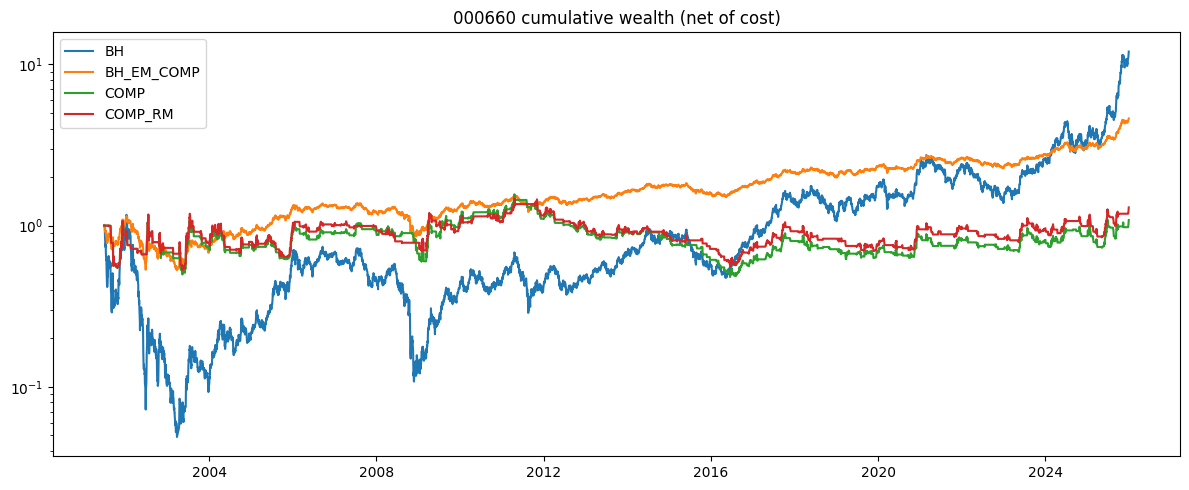

In [9]:
ANN = 252


def summarize(r, w, n_trades, turnover, ann=ANN):
    """일별 수익률 r, 일별 비중 w(종가 후)로 성과 요약. 무위험수익률 0 가정."""
    r = pd.Series(r).reset_index(drop=True)
    w = pd.Series(w).reset_index(drop=True)
    wealth = (1 + r).cumprod()
    n = len(r)
    sd = r.std(ddof=1)
    return {
        "CAGR": wealth.iloc[-1] ** (ann / n) - 1,
        "Vol": sd * np.sqrt(ann),
        "Sharpe": r.mean() / sd * np.sqrt(ann) if sd > 0 else np.nan,
        "MDD": (wealth / wealth.cummax() - 1).min(),
        "Exposure": float(w.mean()),
        "Invested_days": int((w > 0).sum()),
        "Turnover": float(turnover),            # 체결 1회 = 비중 1.0 변화 (전체기간 합)
        "n_trades": int(n_trades),
    }


# ---- 평가 구간 (burn-in 제외) ----
idx = slice(BURN_IN, None)
px = ind["AdjustedClose"].reset_index(drop=True)
bh_ret = px.pct_change().iloc[idx].reset_index(drop=True)   # 평가 첫날은 burn-in 마지막 종가 -> 종가
n_eval = len(bh_ret)
half = ROUND_TRIP_COST / 2


def constant_weight_bh(w_bar):
    """비중 w_bar 를 매일 유지하는 B&H (나머지는 현금, 수익 0). 첫날 w_bar 만큼 매수 비용 부과."""
    r = w_bar * bh_ret
    r.iloc[0] = (1 + r.iloc[0]) * (1 - half * w_bar) - 1
    return r


rows = {}

# BH: 평가 첫날 전액 매수 후 보유
rows["BH"] = summarize(constant_weight_bh(1.0), pd.Series(1.0, index=bh_ret.index),
                       n_trades=1, turnover=1.0)

# COMP / COMP_RM (체결 횟수 = 진입 + 청산(일반 청산 + 손절))
strat = {}
for name, bt in [("COMP", comp), ("COMP_RM", comp_rm)]:
    e = bt.iloc[idx].reset_index(drop=True)
    n_entry = int(e["EntryExec"].sum())
    n_exit = int(e["ExitExec"].sum()) + (int(e["StopExec"].sum()) if "StopExec" in e else 0)
    strat[name] = (e, n_entry, n_exit)

# Exposure-matched BH: 각 전략의 평균 exposure 를 상시 유지
for name in ["COMP", "COMP_RM"]:
    e, _, _ = strat[name]
    w_bar = float(e["WeightClose"].mean())
    rows[f"BH_EM_{name}"] = summarize(constant_weight_bh(w_bar),
                                      pd.Series(w_bar, index=bh_ret.index),
                                      n_trades=1, turnover=w_bar)

for name in ["COMP", "COMP_RM"]:
    e, n_entry, n_exit = strat[name]
    rows[name] = summarize(e["StrategyReturn"], e["WeightClose"],
                           n_trades=n_entry, turnover=n_entry + n_exit)

perf = pd.DataFrame(rows).T
perf.index.name = "strategy"
perf = perf.astype({"Invested_days": int, "n_trades": int})
print(f"평가 구간: {ind['Date'].iloc[BURN_IN].date()} ~ {ind['Date'].iloc[-1].date()}  ({n_eval} 거래일, "
      f"비용 왕복 {ROUND_TRIP_COST:.2%})\n")
print(perf.round(4).to_string())

# 누적 자산곡선 (로그 스케일)
fig, ax = plt.subplots(figsize=(12, 5))
dates = ind["Date"].iloc[BURN_IN:].reset_index(drop=True)
for name, r in [("BH", constant_weight_bh(1.0)),
                ("BH_EM_COMP", constant_weight_bh(float(strat['COMP'][0]['WeightClose'].mean()))),
                ("COMP", strat["COMP"][0]["StrategyReturn"]),
                ("COMP_RM", strat["COMP_RM"][0]["StrategyReturn"])]:
    ax.plot(dates, (1 + r).cumprod(), label=name)
ax.set_yscale("log")
ax.set_title(f"{SYMBOL} cumulative wealth (net of cost)")
ax.legend()
plt.tight_layout()
plt.show()

## Task 9. IS / OOS

마지막 2년 OOS.

각 구간에서 exposure-matched B&H의 exposure를 **별도로** 계산하십시오.

n_trades도 각 기간 실제 entry execution을 다시 세십시오.


**Turnover 주의:** IS/OOS 하위기간의 첫날 이미 보유 중인 포지션을 그 기간의 신규 거래로 계산하지 마십시오.
즉 subperiod turnover는 첫 관측치의 기존 weight를 제외하고 내부 weight 변화만 사용합니다.


In [10]:
ANN = 252

# ---- IS / OOS 분할: 평가기간(burn-in 제외) 중 마지막 2년을 OOS ----
eval_df = ind.iloc[BURN_IN:].reset_index(drop=True)
dates = eval_df["Date"]
cutoff = dates.iloc[-1] - pd.DateOffset(years=2)          # 이 날짜 이후가 OOS
masks = {"IS": (dates <= cutoff).to_numpy(), "OOS": (dates > cutoff).to_numpy()}
for k, m in masks.items():
    print(f"{k:3s}: {dates[m].iloc[0].date()} ~ {dates[m].iloc[-1].date()}  ({int(m.sum())} 거래일)")

# 전략 결과는 전체 구간에서 한 번 돌린 것을 자른다 (IS/OOS 모두 동일 규칙, 포지션은 경계를 넘어 이어짐)
bh_ret_all = ind["AdjustedClose"].pct_change().iloc[BURN_IN:].reset_index(drop=True)
bt_eval = {
    "COMP": comp.iloc[BURN_IN:].reset_index(drop=True),
    "COMP_RM": comp_rm.iloc[BURN_IN:].reset_index(drop=True),
}


def summarize_period(r, w, n_trades, turnover, ann=ANN):
    r = pd.Series(r).reset_index(drop=True)
    w = pd.Series(w).reset_index(drop=True)
    wealth = (1 + r).cumprod()
    sd = r.std(ddof=1)
    return {
        "CAGR": wealth.iloc[-1] ** (ann / len(r)) - 1,
        "Vol": sd * np.sqrt(ann),
        "Sharpe": r.mean() / sd * np.sqrt(ann) if sd > 0 else np.nan,
        "MDD": (wealth / wealth.cummax() - 1).min(),
        "Exposure": float(w.mean()),
        "Invested_days": int((w > 0).sum()),
        "Turnover": float(turnover),
        "n_trades": int(n_trades),
    }


def period_rows(label, m):
    out = []
    bh_p = bh_ret_all[m].reset_index(drop=True)

    # BH: 기간 첫날부터 보유 (기간 시작 매수는 신규 거래로 보지 않음 -> turnover 0, 매수 비용도 부과하지 않음.
    #     Task 8 은 전체기간 첫날 현금에서 매수하는 것으로 보아 비용을 부과하는 점이 다르다)
    out.append(("BH", summarize_period(bh_p, pd.Series(1.0, index=bh_p.index),
                                       n_trades=1, turnover=0.0)))

    # 전략: n_trades 는 해당 기간 안의 실제 entry 체결 수
    #       turnover 는 첫 관측치의 기존 weight 를 제외한 내부 weight 변화 |Δw| 의 합 (같은 날 진입 후 손절은 0)
    for name, bt in bt_eval.items():
        p = bt[m].reset_index(drop=True)
        n_entry = int(p["EntryExec"].sum())
        turn = float(p["WeightClose"].diff().abs().iloc[1:].sum())
        out.append((name, summarize_period(p["StrategyReturn"], p["WeightClose"], n_entry, turn)))

        # exposure-matched BH: 이 기간의 평균 exposure 를 별도로 계산 (미래 기간 정보 사용 안 함)
        w_bar = float(p["WeightClose"].mean())
        out.append((f"BH_EM_{name}", summarize_period(w_bar * bh_p, pd.Series(w_bar, index=bh_p.index),
                                                       n_trades=1, turnover=0.0)))
    return [dict(period=label, strategy=s, **v) for s, v in out]


rows = period_rows("IS", masks["IS"]) + period_rows("OOS", masks["OOS"])
period_perf = pd.DataFrame(rows).set_index(["period", "strategy"])
order = ["BH", "BH_EM_COMP", "BH_EM_COMP_RM", "COMP", "COMP_RM"]
period_perf = period_perf.reindex(
    pd.MultiIndex.from_product([["IS", "OOS"], order], names=["period", "strategy"]))
print("\nOOS cutoff:", cutoff.date())
print(period_perf.round(4).to_string())

# 확인: 기간별 평균 exposure 가 실제로 다른지
print("\n[기간별 평균 exposure]")
print(period_perf.loc[(slice(None), ["COMP", "COMP_RM"]), "Exposure"].unstack("period").round(4))

IS : 2001-06-28 ~ 2023-12-28  (5550 거래일)
OOS: 2024-01-02 ~ 2025-12-30  (486 거래일)

OOS cutoff: 2023-12-30
                        CAGR     Vol  Sharpe     MDD  Exposure  Invested_days  Turnover  n_trades
period strategy                                                                                  
IS     BH             0.0446  0.5660  0.3586 -0.9581    1.0000           5550       0.0         1
       BH_EM_COMP     0.0469  0.1662  0.3586 -0.5309    0.2937           5550       0.0         1
       BH_EM_COMP_RM  0.0435  0.1502  0.3586 -0.4922    0.2654           5550       0.0         1
       COMP          -0.0095  0.2866  0.1093 -0.6928    0.2937           1630     681.0       341
       COMP_RM       -0.0020  0.2747  0.1292 -0.6199    0.2654           1473     609.0       306
OOS    BH             1.2064  0.5218  1.7788 -0.3660    1.0000            486       0.0         1
       BH_EM_COMP     0.3629  0.1836  1.7788 -0.1399    0.3519            486       0.0         1
       BH_EM_

## Task 10. +5일 Volume Event Study

KOSPI200 전체 PIT 데이터 사용.

- VolumeRatio20 > 1.5
- 직전 20 거래관측치 내 이벤트 없음
- UP / DOWN 분리
- +5 거래일 abnormal return
- event-date 평균
- Newey-West t-stat

**구현 정의:** 이벤트 = `VolumeRatio20 > 1.5`인 날 중, 직전 20 거래관측치에 `VolumeRatio20 > 1.5`인 날(spike)이 한 번도 없었던 첫 날. (직전 20일에 "선정된 이벤트"가 없는 날로 읽는 해석과는 이벤트 수가 달라질 수 있습니다.)

In [11]:
from FDA_week04_reference_v21 import add_trading_day_flag

EVENT_THRESHOLD = 1.5    # VolumeRatio20 > 1.5
EXCLUSION_WINDOW = 20    # 직전 20 거래관측치 내 이벤트 없음
HORIZON = 5              # +5 거래일
NW_LAG = 4               # Newey-West lag


def build_event_panel(df_all):
    p = df_all.copy()
    p["Date"] = pd.to_datetime(p["Date"])
    p["Symbol"] = p["Symbol"].astype("string").str.zfill(6)
    p = p.sort_values(["Symbol", "Date"]).reset_index(drop=True)

    # PIT 편입이 끊겼다가 재편입된 종목은 구간(segment)을 나눠 rolling 이 구간을 가로지르지 않게 한다
    cal = {d: i for i, d in enumerate(np.sort(p["Date"].unique()))}
    p["cal_idx"] = p["Date"].map(cal)
    p["seg"] = (p.groupby("Symbol")["cal_idx"].diff().ne(1)).cumsum()

    # 거래정지일은 거래관측치 시계에서 제외
    p = add_trading_day_flag(p)
    p = p.loc[p["TradingDay"]].copy().reset_index(drop=True)
    g = p.groupby(["Symbol", "seg"], sort=False)

    # 수정거래량과 VolumeRatio20 (Task 2 와 동일 정의: 오늘 포함 20 거래관측치 평균)
    factor = p["AdjustedClose"] / p["Close"]
    p["AdjVolume"] = p["Volume"] / factor
    p["AdjVol_MA20"] = g["AdjVolume"].transform(lambda s: s.rolling(20, min_periods=20).mean())
    p["VolumeRatio20"] = p["AdjVolume"] / p["AdjVol_MA20"]

    # 당일 수익률 (UP/DOWN 구분) 과 이후 +5 거래관측치 수익률
    p["Ret"] = g["AdjustedClose"].pct_change()
    p["FwdDate"] = g["Date"].shift(-HORIZON)
    p["StockFwd5"] = g["AdjustedClose"].shift(-HORIZON) / p["AdjustedClose"] - 1.0

    # 이벤트: VolumeRatio20 > 1.5 이면서 직전 20 관측치에 같은 조건이 한 번도 없었던 첫 날
    p["Spike"] = (p["VolumeRatio20"] > EVENT_THRESHOLD).astype(int)
    prior = p.groupby(["Symbol", "seg"], sort=False)["Spike"].transform(
        lambda s: s.shift(1).rolling(EXCLUSION_WINDOW, min_periods=1).max()).fillna(0)
    p["Event"] = (p["Spike"] == 1) & (prior == 0)
    return p


def market_index(p):
    """KOSPI200 PIT 동일가중 시장수익률 (그날 거래된 구성종목 수익률의 단순평균) 과 누적지수."""
    ew = p.groupby("Date")["Ret"].mean()
    return (1.0 + ew.fillna(0.0)).cumprod()


def newey_west_t(x, lag=NW_LAG):
    """평균에 대한 Newey-West(Bartlett) t 통계량."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    u = x - x.mean()
    var = np.dot(u, u) / n
    for l in range(1, lag + 1):
        var += 2.0 * (1.0 - l / (lag + 1.0)) * np.dot(u[l:], u[:-l]) / n
    se = np.sqrt(var / n)
    return x.mean() / se, se


panel = build_event_panel(df_all)
mkt = market_index(panel)

ev = panel.loc[panel["Event"] & panel["FwdDate"].notna() & panel["Ret"].notna() & (panel["Ret"] != 0)].copy()
ev["Direction"] = np.where(ev["Ret"] > 0, "UP", "DOWN")
ev["MktFwd5"] = mkt.reindex(ev["FwdDate"]).to_numpy() / mkt.reindex(ev["Date"]).to_numpy() - 1.0
ev["CAR5"] = ev["StockFwd5"] - ev["MktFwd5"]
ev = ev.dropna(subset=["CAR5"])
event_rows = ev.rename(columns={"VolumeRatio20": "VolumeRatio20_ES"})[
    ["Date", "Symbol", "Name", "VolumeRatio20_ES", "Direction", "Ret", "StockFwd5", "MktFwd5", "CAR5"]
].reset_index(drop=True)

# 이벤트일 단위로 먼저 횡단면 평균 -> 시간순 시계열의 평균과 Newey-West t
out = []
for label, sub in [("UP", event_rows[event_rows["Direction"] == "UP"]),
                   ("DOWN", event_rows[event_rows["Direction"] == "DOWN"]),
                   ("ALL", event_rows)]:
    by_date = sub.groupby("Date")["CAR5"].mean().sort_index()
    t_nw, se = newey_west_t(by_date.values)
    out.append({"Direction": label, "n_events": len(sub), "n_event_dates": len(by_date),
                "mean_CAR5_event_date": by_date.mean(), "NW_se": se, "NW_t": t_nw,
                "mean_CAR5_event_weighted": sub["CAR5"].mean(),
                "mean_StockFwd5": sub["StockFwd5"].mean(), "mean_MktFwd5": sub["MktFwd5"].mean(),
                "hit_ratio(CAR5>0)": (sub["CAR5"] > 0).mean()})
event_summary = pd.DataFrame(out).set_index("Direction")

print("패널 행 수(거래일만):", len(panel), "/ 종목 수:", panel["Symbol"].nunique())
print("Spike(VolumeRatio20>1.5) 일 수:", int(panel["Spike"].sum()), "/ 이벤트(20일 무이벤트 첫날):", int(panel["Event"].sum()))
print("분석에 쓰인 이벤트:", len(event_rows), "\n")
print(event_summary.round(4).T.to_string())
print()
print(event_rows.head(10).to_string(index=False))

패널 행 수(거래일만): 1230778 / 종목 수: 527
Spike(VolumeRatio20>1.5) 일 수: 165677 / 이벤트(20일 무이벤트 첫날): 17808
분석에 쓰인 이벤트: 17429 

Direction                         UP       DOWN         ALL
n_events                  10402.0000  7027.0000  17429.0000
n_event_dates              4092.0000  3306.0000   5056.0000
mean_CAR5_event_date         -0.0010     0.0003     -0.0003
NW_se                         0.0008     0.0008      0.0006
NW_t                         -1.2798     0.3733     -0.4205
mean_CAR5_event_weighted     -0.0005     0.0007     -0.0000
mean_StockFwd5                0.0039     0.0038      0.0039
mean_MktFwd5                  0.0044     0.0031      0.0039
hit_ratio(CAR5>0)             0.4500     0.4755      0.4603

      Date Symbol    Name  VolumeRatio20_ES Direction       Ret  StockFwd5   MktFwd5      CAR5
2001-04-03 000010 (주)신한은행          2.453778        UP  0.149051  -0.061321 -0.008281 -0.053039
2001-07-27 000010 (주)신한은행          1.536820        UP  0.035477   0.104925  0.036834  0.0680

## Task 11. 결과 해석

본인 종목의 실제 날짜와 수치를 사용해 답하십시오.

1. 거래량은 가격지표에 어떤 추가 정보를 주었는가?
2. COMP는 어떤 시장국면에서 BH보다 우수/열위였는가?
3. COMP_RM은 MDD와 수익률을 어떻게 바꾸었는가?
4. 비용 0×/1×/2×가 결론을 바꾸었는가?
5. 지표 중복성이 관찰되었는가?
6. IS 성과가 OOS에서도 유지되었는가?
7. 2년 OOS 결과를 과도하게 일반화하면 안 되는 이유는 무엇인가?


### Task 11 답안 (000660, 평가기간 2001-06-28 ~ 2025-12-30, burn-in 120일 제외, 왕복 비용 0.25%)

**1. 거래량은 가격지표에 어떤 추가 정보를 주었는가?**

- **정보 측면**: VolumeRatio20은 SMA gap, MACD, RSI, MFI, ATR%와 상관의 절댓값이 0.07 이하(Task 3)여서 가격지표와 겹치지 않는 별도 정보입니다. 다만 MFI14는 RSI14와 상관이 0.77로, 거래량이 들어갔어도 가격지표(RSI)와 많이 겹칩니다.
- **예측력**: KOSPI200 전체의 거래량 급증 이벤트 17,429건에서 +5일 초과수익은 UP −0.10%(Newey-West t = −1.28), DOWN +0.03%(t = 0.37)로 유의하지 않았습니다(Task 10). 거래량 급증만으로는 이후 5일의 방향을 알 수 없었습니다.
- **성과 기여**: 거래량 신호를 뺀 COMP를 따로 돌리지 않았으므로 COMP 성과에 대한 기여를 분리해 말할 수 없습니다. COMP(CAGR 0.33%)가 같은 노출도의 BH(6.6%)보다 낮았다는 점만 확인됩니다(Task 8).

**2. COMP는 어떤 시장국면에서 BH보다 우수/열위였는가?**

노트북에는 하락장/상승장을 따로 나눈 계산이 없어, 전체기간과 IS/OOS 구간(Task 8, 9)으로만 비교합니다.

| | BH | 같은 노출도 BH | COMP |
|---|---|---|---|
| 전체 CAGR | 10.9% | 6.6% | 0.33% |
| 전체 MDD | −95.8% | −53.7% | −69.3% |
| 전체 Vol | 56.3% | 16.8% | 28.6% |
| IS CAGR (2001-06-28~2023-12-28) | 4.5% | 4.7% | −0.95% |
| OOS CAGR (2024-01-02~2025-12-30) | 120.6% | 36.3% | 16.2% |

- **우수했던 점**: BH 대비 낙폭이 작았습니다(전체 MDD −69.3% vs −95.8%, 변동성 28.6% vs 56.3%). 평균 노출도가 29.8%에 불과해 위험이 작았던 결과입니다.
- **열위했던 점**: 수익률은 IS와 OOS 모두 BH보다 낮았습니다. 특히 BH가 120.6% 오른 OOS에서는 COMP 16.2%로 격차가 컸습니다(강한 상승 구간에서 열위).
- **같은 노출도의 BH와 비교**: COMP는 전체(0.33% vs 6.6%), IS(−0.95% vs 4.7%), OOS(16.2% vs 36.3%) 모두 같은 노출도의 BH보다 낮았고, MDD도 더 컸습니다(−69.3% vs −53.7%). 낙폭이 작아 보이는 것은 타이밍이 아니라 주식을 적게 들고 있었기 때문으로 해석됩니다.

**3. COMP_RM은 MDD와 수익률을 어떻게 바꾸었는가?**

| | COMP | COMP_RM |
|---|---|---|
| MDD | −69.3% | −62.0% |
| 누적수익률 | +8.3% | +29.7% |
| CAGR / Sharpe | 0.33% / 0.154 | 1.09% / 0.176 |
| Vol | 28.6% | 27.4% |
| 노출도 | 0.298 | 0.269 |
| 진입 횟수 | 363 | 324 |

- HighVol gate가 진입 신호 141개를 막았습니다. 청산은 Score<2 일반 청산 300회, 장중 손절 16회(그중 same-day stop 1회), 갭 손절 7회였습니다.
- 갭 손절은 손절가가 지켜지지 않았습니다. 2002-10-30에는 손절가 9,706원인데 시가 9,423원에서 체결됐습니다.
- MDD는 개선됐지만(−69.3% → −62.0%) 여전히 −62.0%로 큽니다.

**4. 비용 0×/1×/2×가 결론을 바꾸었는가?**

| | CAGR | Sharpe | MDD |
|---|---|---|---|
| COMP 0× / 1× / 2× | 4.20% / 0.33% / −3.40% | 0.286 / 0.154 / 0.022 | −62.6% / −69.3% / −76.9% |
| COMP_RM 0× / 1× / 2× | 4.57% / 1.09% / −2.27% | 0.299 / 0.176 / 0.053 | −54.4% / −62.0% / −71.2% |

- **바뀐 것**: 절대 수익입니다. 비용 0×에서는 양(+)의 수익이었지만 1×에서 거의 사라지고 2×에서는 손실입니다. 0× 대비 CAGR 하락은 1×에서 COMP −3.87%p, COMP_RM −3.47%p, 2×에서 −7.60%p, −6.84%p였습니다.
- **안 바뀐 것**: 모든 비용 수준에서 COMP_RM이 COMP보다 나았습니다. 그리고 비용이 0이어도 COMP(4.20%)와 COMP_RM(4.57%)은 BH(10.9%)와 같은 노출도의 BH(6.6%)보다 낮았습니다. 거래가 많아(363회) 비용에 민감하지만, 열위의 원인이 비용만은 아닙니다.

**5. 지표 중복성이 관찰되었는가?**

네. RSI14와 MFI14의 상관이 0.77로 가장 높았습니다(MFI는 거래량이 가중된 RSI). SMA gap과 RSI14가 0.51, SMA gap과 ATR%가 −0.40이었습니다. 반대로 VolumeRatio20은 다른 지표와 거의 무상관(|ρ|≤0.07)이었습니다. 단 이 상관은 2001~2025년 전체 평균이며, 시계열의 자기상관 때문에 정밀도를 과신할 수 없습니다.

**6. IS 성과가 OOS에서도 유지되었는가?**

| | IS (2001-06-28~2023-12-28) | OOS (2024-01-02~2025-12-30) |
|---|---|---|
| COMP CAGR / Sharpe | −0.95% / 0.109 | 16.2% / 0.676 |
| COMP_RM CAGR / Sharpe | −0.20% / 0.129 | 17.0% / 0.722 |
| 같은 노출도 BH CAGR | 4.7% | 36.3% |
| BH CAGR | 4.5% | 120.6% |

- 절대 수익은 OOS에서 양(+)으로 개선됐습니다.
- 그러나 **같은 노출도의 BH보다 낮다는 점은 IS와 OOS 모두 유지**됐습니다(IS −0.95% vs 4.7%, OOS 16.2% vs 36.3%). OOS의 MDD도 COMP −28.0%로 같은 노출도 BH의 −14.0%보다 컸습니다.
- 따라서 "IS의 성과가 유지됐다"기보다 "IS의 열위가 OOS에서도 이어졌다"가 정확합니다. 한편 IS 구간에서 규칙을 최적화하지 않았기 때문에 전형적인 과적합 검증은 아닙니다.

**7. 2년 OOS 결과를 과도하게 일반화하면 안 되는 이유**

1. **표본이 작습니다**: OOS는 486거래일이고 진입은 22회(COMP)·18회(COMP_RM)뿐입니다. IS는 5,550거래일, 진입 341회·306회입니다.
2. **특수한 시장 국면입니다**: OOS는 이 종목이 크게 오른 시기입니다(BH CAGR 120.6%, IS는 4.5%). 상승장에서의 성과를 일반 성과로 볼 수 없습니다.
3. **단일 종목, 단일 경로입니다**: 000660 하나의 한 번뿐인 시계열이라 다른 종목이나 다른 경로에서 같은 결과가 나온다는 보장이 없습니다.
4. **IS와 OOS의 차이가 큽니다**: COMP의 CAGR이 IS −0.95%, OOS 16.2%로 크게 다르고, 노출도도 IS 0.294, OOS 0.352로 다릅니다. 짧은 구간의 결과는 우연의 영향이 큽니다.
5. **규칙 선택의 영향이 있습니다**: ATR 배수, reset 조건, 비용 가정이 결과에 영향을 주며, 이 값들은 과제 문서에 명시되지 않았습니다. ATR 배수는 toy 검증을 통과하는 범위(1.25~3.0) 안에서 2.0을 택한 것이며, toy가 이 값을 확정해 주지는 않습니다. 또 toy에는 갭 손절 사례가 없어 갭 손절 로직은 toy로 검증되지 않았습니다.


## Task 12. 표준 출력

In [12]:
import json


def to_native(d):
    """numpy 숫자를 파이썬 기본형으로 변환 (정수 항목은 int, 나머지는 float)."""
    int_keys = {"Invested_days", "n_trades", "n_events", "n_event_dates"}
    return {k: (int(v) if k in int_keys else float(v)) for k, v in d.items()}


perf_cols = ["CAGR", "Vol", "Sharpe", "MDD", "Exposure", "Invested_days", "Turnover", "n_trades"]


def row(table, name):
    return to_native(table.loc[name, perf_cols].to_dict())


def period_block(period):
    t = period_perf.loc[period]
    return {
        "BH": row(t, "BH"),
        "BH_EXPOSURE_MATCHED": row(t, "BH_EM_COMP"),          # COMP 의 exposure 기준 (제출 표준)
        "BH_EXPOSURE_MATCHED_COMP_RM": row(t, "BH_EM_COMP_RM"),  # 참고: COMP_RM 의 exposure 기준
        "COMP": row(t, "COMP"),
        "COMP_RM": row(t, "COMP_RM"),
    }


event_cols = ["n_events", "n_event_dates", "mean_CAR5_event_date", "NW_t"]

results = {
    "symbol": SYMBOL,
    "n_obs": int(len(raw)),               # Task 1: 원자료(raw) 행 수
    "n_trading_days": int(len(trd)),      # Task 1: 거래정지 제외 거래일 수
    "BH": row(perf, "BH"),
    "BH_EXPOSURE_MATCHED": row(perf, "BH_EM_COMP"),          # COMP 의 평균 exposure 에 맞춘 BH (제출 표준)
    "BH_EXPOSURE_MATCHED_COMP_RM": row(perf, "BH_EM_COMP_RM"),  # 참고: COMP_RM 의 평균 exposure 에 맞춘 BH
    "COMP": row(perf, "COMP"),
    "COMP_RM": row(perf, "COMP_RM"),
    "IS": period_block("IS"),
    "OOS": period_block("OOS"),
    "EVENT_STUDY": {d: to_native(event_summary.loc[d, event_cols].to_dict()) for d in ["UP", "DOWN"]},
}

print(json.dumps(results, indent=2, ensure_ascii=False))

{
  "symbol": "000660",
  "n_obs": 6168,
  "n_trading_days": 6156,
  "BH": {
    "CAGR": 0.10931958883682946,
    "Vol": 0.5626829656582827,
    "Sharpe": 0.4643896395048805,
    "MDD": -0.9581398287682051,
    "Exposure": 1.0,
    "Invested_days": 6036,
    "Turnover": 1.0,
    "n_trades": 1
  },
  "BH_EXPOSURE_MATCHED": {
    "CAGR": 0.06598589641422947,
    "Vol": 0.16789132267624715,
    "Sharpe": 0.46438940173210663,
    "MDD": -0.5370267981864231,
    "Exposure": 0.29837640821736244,
    "Invested_days": 6036,
    "Turnover": 0.2983764082173625,
    "n_trades": 1
  },
  "BH_EXPOSURE_MATCHED_COMP_RM": {
    "CAGR": 0.06060018223301977,
    "Vol": 0.15129795487622086,
    "Sharpe": 0.4643893917383377,
    "MDD": -0.49707331227839646,
    "Exposure": 0.26888667992047716,
    "Invested_days": 6036,
    "Turnover": 0.26888667992047716,
    "n_trades": 1
  },
  "COMP": {
    "CAGR": 0.0033277249476566517,
    "Vol": 0.2859893522415362,
    "Sharpe": 0.1538306009352222,
    "MDD": -0.69